<a href="https://colab.research.google.com/github/xzhen-hub/ML_Linear-Factor-Model/blob/main/g1_fannie_full53_colab_20261101.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fannie G1 full53 comparison — Google Colab entry point
Prepared November 1, 2026. Use THIS notebook at https://colab.research.google.com/ . No BigQuery Studio notebook permissions, Cloud Storage bucket or service-account key is needed. Sign in to BigQuery using your existing authorized Google account at Step5.

**Period: January2022-May2026 inclusive, all53 calendar months.** Both saved models score the same eligible loans, labels, features and current-UPB weights within each populated month. Read original production data/model from oasive_quant_bq; create the one permanent research panel ONLY in oasive_quant_sandbox. Python loads/scores the saved expanded model in Colab. No training, recalibration or production changes occur.

## Start here
1. In Colab choose File > Upload notebook and select this `.ipynb`. Rename/save it so you can find it in Google Drive later. Use a standard Python CPU runtime; no GPU is required for this inference workflow.
2. Through the Colab Files sidebar upload BOTH original FULL archives to /content and wait for completion: g1_sample_expansion_uxtgy0f6_FULL_recovery.zip and g1_production_vs_expanded_v1_FULL_recovery.zip. Uploading the notebook does not upload these data/model backups.
3. Run Steps1-5 first. Step2 can install the exact saved packages and require ONE session restart; then rerun Steps1-2 and continue. Do not retrain to recover a missing model or encoder.
4. Review read estimates at Step6 before the large jobs. Original estimates were roughly44GiB census,34GiB mapping and315GiB panel freeze, with later reads/storage costs additional. The large join runs in BigQuery; Colab downloads one populated month at a time.
5. Run Step16 after useful checkpoints and at completion. Create the archives, then run SMALL and FULL download cells separately. Save BOTH downloaded ZIPs to Y:/OASIVE. Runtime files and Python variables are temporary, even when the notebook code is saved.

## Scope to keep explicit
- Original corrected verified Fannie G1: CL30YR pass-through pools, actual-coupon buckets6.0/6.5, adjusted vintage2024, known-target mapping. Dynamic historical membership; no March-survivor filter.
- These target pools first appear in December2023. Earlier calendar months remain explicit empty rows with blank accuracy metrics. A broader full-Fannie book is a different evaluation scope.
- The historical feature snapshot can differ from the inputs used in the prior March result. Original model replay and the reconstructed March bridge are mandatory; both models are rescored on common inputs. Unexpected non-HPI changes stop.
- Both Fannie source windows match January2022-May2026, but the saved local candidate also differs in agency coverage, engine, retention realization and stopping settings. This is practical candidate accuracy, not a causal split-only experiment or an untouched future test. June calibration and post-May evaluation remain separate.

Follow the numbered steps below in order. Keep older completed notebooks/backups; this is a separate run root. Resume this edition only from its own FULL output checkpoint. The two ORIGINAL input archives remain the same.


## Step 1 â€” Upload the two existing FULL backups and recover selected assets
Upload through the Files sidebar and wait until each upload finishes:
1. `Y:/OASIVE/g1_sample_expansion_uxtgy0f6_FULL_recovery.zip`
2. `Y:/OASIVE/g1_production_vs_expanded_v1_FULL_recovery.zip`

Use the exact `/content/` filenames below; change the path if Colab appends `(1)`. Small-results ZIPs and the owner's pool prediction ZIP are insufficient for model recovery.

For a FIRST run keep RESTORE_MONTHLY_ZIP_PATH=None. To resume this NEW53-month experiment after shutdown, upload its downloaded FULL recovery ZIP and set that variable to the uploaded path. The root folder must stay the same for the saved paths and checksums.


In [1]:
from pathlib import Path
import sys,json,zipfile,hashlib,shutil,importlib,importlib.util,subprocess,gc
ROOT=Path('/content/g1_fannie_full53_colab_20261101')
ROOT.mkdir(exist_ok=True)
EXP_FULL=Path('/content/g1_sample_expansion_uxtgy0f6_FULL_recovery.zip')
PROD_FULL=Path('/content/g1_production_vs_expanded_v1_FULL_recovery.zip')
RESTORE_MONTHLY_ZIP_PATH=None

def file_sha(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
    return h.hexdigest()

def restore_selected(archive,mapping,manifest_name,out):
    archive=Path(archive);out=Path(out);out.mkdir(parents=True,exist_ok=True)
    assert archive.is_file() and zipfile.is_zipfile(archive),f'Upload is missing/incomplete or not a readable ZIP: {archive}'
    with zipfile.ZipFile(archive) as z:
        hashes=json.loads(z.read(manifest_name))
        for local,member in mapping.items():
            assert member in hashes,'Wrong backup; missing '+member
            dest=out/local
            if not dest.exists():
                temp=dest.with_name(dest.name+'.recovering');dest.parent.mkdir(parents=True,exist_ok=True)
                with z.open(member) as src,temp.open('wb') as dst:shutil.copyfileobj(src,dst,length=1024*1024)
                assert file_sha(temp)==hashes[member],'Recovery checksum mismatch: '+member
                temp.replace(dest)
            assert file_sha(dest)==hashes[member],'Conflicting recovered file: '+str(dest)

if RESTORE_MONTHLY_ZIP_PATH:
    archive=Path(RESTORE_MONTHLY_ZIP_PATH)
    assert zipfile.is_zipfile(archive),'Wait until the NEW monthly full recovery ZIP finishes uploading.'
    with zipfile.ZipFile(archive) as z:
        hashes=json.loads(z.read('monthly_recovery_hashes.json'))
        for name,digest in hashes.items():
            dest=(ROOT/name).resolve()
            assert dest.is_relative_to(ROOT.resolve()),'Unsafe recovery path'
            if not dest.exists():
                dest.parent.mkdir(parents=True,exist_ok=True)
                temp=dest.with_name(dest.name+'.recovering')
                with z.open(name) as src,temp.open('wb') as dst:shutil.copyfileobj(src,dst,length=1024*1024)
                assert file_sha(temp)==digest,'Recovery checksum mismatch: '+name
                temp.replace(dest)
            assert file_sha(dest)==digest,'Conflicting recovery file: '+name
else:
    restore_selected(EXP_FULL,{
        'manifest.json':'original_saved_experiment/manifest.json',
        'post_rally_matched_test.py':'original_saved_experiment/post_rally_matched_test.py',
        'expanded.ubj':'sample_expansion_25features_seed20261021/fannie_expanded_25features.ubj',
        'encoder.joblib':'sample_expansion_25features_seed20261021/fixed_fannie_encoder.joblib',
        'experiment_spec.json':'sample_expansion_25features_seed20261021/experiment_spec.json'},
        'full_recovery_file_hashes.json',ROOT/'recovered/expanded')
    restore_selected(PROD_FULL,{
        'march_golden.parquet':'paired_production_expanded_march.parquet',
        'production_model_metadata.json':'production_scoring/production_model_metadata.json'},
        'comparison_file_hashes.json',ROOT/'recovered/production')
MANIFEST=json.loads((ROOT/'recovered/expanded/manifest.json').read_text())
print('Recovery ready:',ROOT)


Recovery ready: /content/g1_fannie_full53_colab_20261101


## Step 2 â€” Restore the exact saved package versions
Run before loading pandas, sklearn, the encoder or XGBoost. If installation occurs, choose Runtime > Restart session ONCE, rerun Steps 1-2, then continue. Do not disconnect/delete the runtime and do not retrain to work around a package mismatch.


In [2]:
import importlib.metadata
requirements=[]
for name,version in MANIFEST['versions'].items():
    try:current=importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:current=None
    if current!=version:requirements.append(name+'=='+version)
if requirements:
    subprocess.run([sys.executable,'-m','pip','install','--quiet',*requirements],check=True)
    raise RuntimeError('Packages restored. Restart session, rerun Steps 1-2, then continue.')
print('Recorded model package versions match.')


Recorded model package versions match.


## Step 3 â€” Install the included comparison helpers into this runtime
Run BOTH cells below exactly once after setup. They only write Python files inside `/content`; they do not submit queries or fit models. The first is the tested saved-model/metric engine; the second implements the 53-month calendar and reconstructed sources. Do not replace their month constants with the older12-month loop.


In [3]:
%%writefile /content/g1_saved_payoff_comparison_core.py
"""Shared saved-payoff scoring and metrics. No evaluation-calendar constants or training."""

from pathlib import Path

import json,hashlib,os

import numpy as np

import pandas as pd

PROJECT='gen-lang-client-0343560978'

MODEL=PROJECT+'.oasive_quant_bq.conv_prepay_30y_v2_payoff_prod_t360_v2_20261002'

KEY=['agency','loan_id','feature_date']

CAT=['loan_purpose','state','occupancy','channel','property_type']

BASE='orig_rate orig_fico orig_ltv orig_dti orig_upb loan_purpose state occupancy channel property_type num_units current_rate dlq_days ust_10y primary_mortgage_rate note_rate_minus_pmms loan_age seasonality_sin seasonality_cos sato current_ltv_hpi hpa_state_12m rolling_incentive_12m burnout media_effect_months'.split()

POS=['refinance','turnover','cashout','buyout']

BROAD=POS+['turnover_proxy','voluntary_unknown']

HASHES={'model':'8d459d82ddc2b3611afc3777683665fd266bb99cb2797d6e776622f43855b005','encoder':'a0b6e2b741ec5990e32f290912e955c0a768bb0ea9ada74f05dad95591fce07c','module':'c72ebd1e2250544fb4ca4d8746e4bdc8829f6141cd845d6028d1afa2ac83d2e7','march':'4be2db689247e6bbbd7e9b79ea05783452cdb4c9fff1f57b35f37dabb68b092d'}

MAX_BYTES=10*1024**3

def sha(path):
 h=hashlib.sha256()
 with Path(path).open('rb') as f:
  for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
 return h.hexdigest()

def write_json(path,data):
 path=Path(path);tmp=path.with_suffix(path.suffix+'.tmp');tmp.write_text(json.dumps(data,indent=2,default=str),encoding='utf-8');os.replace(tmp,path)

def canonical(x):
 if isinstance(x,list):return [canonical(v) for v in x]
 if isinstance(x,dict):
  r={k:canonical(v) for k,v in x.items()}
  if 'name' in r and 'type' in r:r.setdefault('mode','NULLABLE')
  return r
 return x

def table_id(table):
 d=table.to_api_repr();return canonical({k:d.get(k) for k in ['id','lastModifiedTime','numRows','schema','timePartitioning']})

def model_id(model):
 d=model.to_api_repr();return canonical({k:d.get(k) for k in ['modelReference','modelType','creationTime','lastModifiedTime','etag','featureColumns']})

def normalize(f):
 f=f.copy()
 for c in ['agency','loan_id']:
  if f[c].isna().any():raise ValueError('Missing identity '+c)
  f[c]=f[c].astype(str)
 f['feature_date']=pd.to_datetime(f.feature_date).dt.strftime('%Y-%m-%d')
 if f.feature_date.isna().any() or f.duplicated(KEY).any():raise ValueError('Missing/duplicate monthly identity')
 return f

def score_expanded(model,encoder,m,f,batch=75000):
 import xgboost as xgb
 if m.BASE!=BASE or m.Q!=.12:raise ValueError('Wrong saved training module contract')
 raw=[]
 for i in range(0,len(f),batch):raw.append(model.predict(xgb.DMatrix(m.matrix(f.iloc[i:i+batch],encoder,'baseline'))))
 return m.odds(np.concatenate(raw),.12)

def join_predictions(f,prod,expanded):
 prod=normalize(prod)
 z=normalize(f).merge(prod,on=KEY,how='outer',indicator=True,validate='one_to_one',suffixes=('','_production'))
 if not z._merge.eq('both').all():raise ValueError('Predictions do not cover exactly the month')
 for c in ['pool_id','pool_coupon']:
  if c+'_production' in z and not z[c].eq(z[c+'_production']).all():raise ValueError('Prediction membership differs '+c)
 if not np.allclose(z.current_upb,z.current_upb_production,atol=.02,rtol=0):raise ValueError('Prediction weights differ')
 z=z.drop(columns=['_merge']+[c for c in z if c.endswith('_production')])
 # Use keyed expansion values; never rely on the cloud query row order.
 local=normalize(f)[KEY].copy();local['expanded_before']=expanded
 z=z.merge(local,on=KEY,validate='one_to_one')
 for c in ['production_before','expanded_before']:
  if not np.isfinite(z[c]).all() or not z[c].between(0,1).all():raise ValueError('Invalid payoff probabilities')
 return z

def metric(g):
 w=g.current_upb.to_numpy(float);y=g.actual_payoff.to_numpy(float);avg=lambda v:float(np.average(v,weights=w))
 out=dict(loans=len(g),payoff_events=int(y.sum()),upb=float(w.sum()),actual_payoff_pct=100*avg(y),effective_loans=float(w.sum()**2/(w@w)))
 out['small_group_attention']=bool(out['payoff_events']<30 or out['effective_loans']<30)
 for arm in ['production','expanded']:
  p=g[arm+'_before'].to_numpy(float);q=np.clip(p,1e-12,1-1e-12)
  out[arm+'_predicted_pct']=100*avg(q);out[arm+'_bias_pp']=100*(avg(q)-avg(y));out[arm+'_brier']=avg((q-y)**2);out[arm+'_logloss']=avg(-y*np.log(q)-(1-y)*np.log1p(-q))
 out['abs_bias_gain_pp']=abs(out['production_bias_pp'])-abs(out['expanded_bias_pp'])
 for loss in ['brier','logloss']:out[loss+'_gain']=out['production_'+loss]-out['expanded_'+loss]
 return out

def group_report(f,month):
 f=f.reset_index(drop=True);age=pd.to_numeric(f.loan_age);size=pd.to_numeric(f.orig_upb);inc=pd.to_numeric(f.note_rate_minus_pmms)
 ab=pd.cut(age,[-np.inf,12,24,60,np.inf],right=False,labels=['lt12','12_23','24_59','60plus']).astype(object).fillna('missing')
 bb=pd.cut(size,[-np.inf,150000,300000,500000,np.inf],right=False,labels=['lt150k','150_300k','300_500k','500kplus']).astype(object).fillna('missing')
 groups=[('overall','all',np.ones(len(f),bool))]
 for coupon,lo,hi in [(6.,.5,1.),(6.5,1.,1.5)]:
  cp=f.pool_coupon.eq(coupon);groups.append(('coupon',str(coupon),cp));focus=cp&f.dlq_days.eq(0)&age.ge(12)&age.lt(24)&inc.ge(lo)&inc.lt(hi)
  for b in bb.unique():groups.append(('focus_current_young',str(coupon)+'_'+b,focus&bb.eq(b)))
  for a in ab.unique():
   for b in bb.unique():groups.append(('age_original_balance',f'{coupon}_{a}_{b}',cp&ab.eq(a)&bb.eq(b)))
  for status,mask in [('current',f.dlq_days.eq(0)),('delinquent',f.dlq_days.gt(0)),('unknown',f.dlq_days.isna()|f.dlq_days.lt(0))]:groups.append(('status',str(coupon)+'_'+status,cp&mask))
  for c in ['state','property_type','occupancy','channel']:
   values=f[c].astype(object).fillna('<missing>')
   for value in values.unique():groups.append((c,str(coupon)+'_'+str(value),cp&values.eq(value)))
 return pd.DataFrame([dict(month=month,stage='before',grouping=k,group=v,**metric(f.loc[mask])) for k,v,mask in groups if np.any(mask)])

def model_id_from_dict(d):return canonical({k:d.get(k) for k in ['modelReference','modelType','creationTime','lastModifiedTime','etag','featureColumns']})

def cached_query(client,name,q,root):
 from google.cloud import bigquery
 root=Path(root);folder=root/'query_cache';folder.mkdir(exist_ok=True)
 path=folder/(name+'.parquet');done=folder/(name+'_complete.json');started=folder/(name+'_job.json');digest=hashlib.sha256(q.encode()).hexdigest()
 if done.exists():
  d=json.loads(done.read_text())
  if d['sql_sha256']!=digest or sha(path)!=d['file_sha256']:raise ValueError('Changed cached query '+name)
  return pd.read_parquet(path)
 if started.exists():
  d=json.loads(started.read_text())
  if d['sql_sha256']!=digest:raise ValueError('Changed checkpoint SQL')
  job=client.get_job(d['job_id'],location='us-central1')
 else:
  job=client.query(q,job_config=bigquery.QueryJobConfig(maximum_bytes_billed=MAX_BYTES),location='us-central1')
  write_json(started,dict(job_id=job.job_id,sql_sha256=digest))
 print('Query:',name,'job:',job.job_id,flush=True)
 chunks=[pd.DataFrame([dict(r) for r in page]) for page in job.result(page_size=10000).pages]
 frame=pd.concat(chunks,ignore_index=True) if chunks else pd.DataFrame();frame.to_parquet(path,index=False)
 write_json(done,dict(job_id=job.job_id,sql_sha256=digest,file_sha256=sha(path),rows=len(frame),total_bytes_processed=job.total_bytes_processed))
 return frame


Writing /content/g1_saved_payoff_comparison_core.py


In [4]:
%%writefile /content/g1_fannie_full53.py
"""Retrospective 53-calendar-month Fannie G1 comparison. Saved models only."""
from pathlib import Path
import json,hashlib,re,os
import numpy as np
import pandas as pd
import g1_saved_payoff_comparison_core as core
PROJECT=core.PROJECT
FEATURES=PROJECT+'.oasive_quant_bq.feature_loan_month_mat_bak20261005_171029'
LABELS=PROJECT+'.oasive_quant_bq.label_loan_month_fast_bak20261010_193027'
SERVICING=PROJECT+'.oasive_quant_bq.fact_loan_monthly_fannie_sftp'
POOLS=PROJECT+'.oasive_quant_sandbox.g1_original_components_20261016_v2_pool_metadata'
POOL_ALL=PROJECT+'.oasive_quant_sandbox.g1_nnm_original_period_20261010_fannie_pool_metadata'
MODEL=core.MODEL
MONTHS=[d.strftime('%Y-%m-%d') for d in pd.date_range('2022-01-01','2026-05-01',freq='MS')]
SOURCES=[FEATURES,LABELS,SERVICING,POOLS,POOL_ALL]
FREEZE_MAX=500*1024**3;REPORT_MAX=10*1024**3;TOTAL_ESTIMATE_MAX=750*1024**3

def roster_sql():
 return f"""SELECT pool_id,coupon pool_coupon,actual_coupon,issue_date,adjusted_year,prefix,product_term,security_structure,mapping_status
 FROM `{POOLS}` ORDER BY pool_id"""

def validate_roster(p):
 if p.empty or p.pool_id.isna().any() or p.pool_id.duplicated().any():raise ValueError('Empty/duplicate pool metadata')
 k=p.loc[p.mapping_status.eq('known_target')].copy()
 if k.empty or not k.adjusted_year.eq(2024).all() or not k.prefix.eq('CL').all() or not k.product_term.eq('30YR').all() or not k.security_structure.eq('PASS_THROUGH').all():raise ValueError('Original corrected G1 definition changed')
 if not k.pool_coupon.isin([6.,6.5]).all() or k.issue_date.isna().any():raise ValueError('Invalid target pool metadata')
 c=pd.to_numeric(k.actual_coupon)
 if not (((k.pool_coupon.eq(6.))&c.ge(5.75)&c.lt(6.25))|((k.pool_coupon.eq(6.5))&c.ge(6.25)&c.lt(6.75))).all():raise ValueError('Actual pool coupon does not match monitor bucket')
 return k

def members_cte():
 return f"""WITH target AS (
 SELECT pool_id,coupon AS pool_coupon,actual_coupon,issue_date FROM `{POOLS}` WHERE mapping_status='known_target'
 ), raw_members AS (
 SELECT 'fannie' agency,CAST(a.loan_id AS STRING) loan_id,a.as_of_date feature_date,a.pool_id,
 p.pool_coupon,p.actual_coupon,p.issue_date,CAST(a.current_upb AS FLOAT64) current_upb,
 EXISTS(SELECT 1 FROM `{SERVICING}` prior WHERE prior.loan_id=a.loan_id
 AND prior.as_of_date=DATE_SUB(a.as_of_date,INTERVAL 1 MONTH) AND prior.current_upb>0) has_prior
 FROM `{SERVICING}` a JOIN target p ON a.pool_id=p.pool_id
 WHERE a.as_of_date BETWEEN DATE '2022-01-01' AND DATE '2026-05-01'
 AND a.as_of_date=DATE_TRUNC(a.as_of_date,MONTH) AND a.orig_term=360
 AND a.current_upb>0 AND p.issue_date<=a.as_of_date
 ), members AS (SELECT * EXCEPT(has_prior) FROM raw_members WHERE has_prior)"""

def census_sql():
 return members_cte()+""", calendar AS (
 SELECT month FROM UNNEST(GENERATE_DATE_ARRAY(DATE '2022-01-01',DATE '2026-05-01',INTERVAL 1 MONTH)) month
 ), raw_counts AS (SELECT feature_date month,pool_coupon,COUNT(*) raw_target_rows,COUNTIF(NOT has_prior) excluded_no_prior_rows FROM raw_members GROUP BY 1,2), counts AS (
 SELECT feature_date month,pool_coupon,COUNT(*) member_rows,COUNT(DISTINCT loan_id) distinct_member_loans,SUM(current_upb) member_upb
 FROM members GROUP BY 1,2)
 SELECT c.month feature_date,k pool_coupon,
 (SELECT COUNT(*) FROM target t WHERE t.pool_coupon=k AND t.issue_date<=c.month) issued_target_pools,
 COALESCE(r.raw_target_rows,0) raw_target_rows,COALESCE(r.excluded_no_prior_rows,0) excluded_no_prior_rows,
 COALESCE(n.member_rows,0) member_rows,COALESCE(n.distinct_member_loans,0) distinct_member_loans,COALESCE(n.member_upb,0) member_upb
 FROM calendar c CROSS JOIN UNNEST([6.0,6.5]) k LEFT JOIN counts n ON n.month=c.month AND n.pool_coupon=k
 LEFT JOIN raw_counts r ON r.month=c.month AND r.pool_coupon=k
 ORDER BY 1,2"""

def mapping_audit_sql():
 return f"""SELECT a.as_of_date feature_date,COUNT(*) candidate_rows,
 COUNTIF(s.mapping_status='known_target') verified_target_rows,
 COUNTIF(s.mapping_status='known_other_year') known_other_year_rows,
 COUNTIF(s.pool_id IS NULL OR s.mapping_status NOT IN('known_target','known_other_year')) unresolved_candidate_rows,
 SUM(IF(s.pool_id IS NULL OR s.mapping_status NOT IN('known_target','known_other_year'),CAST(a.current_upb AS FLOAT64),0)) unresolved_upb
 FROM `{SERVICING}` a JOIN `{POOL_ALL}` p USING(pool_id)
 LEFT JOIN `{POOLS}` s USING(pool_id)
 WHERE a.as_of_date BETWEEN DATE '2022-01-01' AND DATE '2026-05-01'
 AND a.as_of_date=DATE_TRUNC(a.as_of_date,MONTH) AND a.orig_term=360 AND a.current_upb>0
 AND STARTS_WITH(a.pool_id,'CL') AND p.coupon>=5.75 AND p.coupon<6.75
 AND p.issue_date>=DATE '2023-12-01' AND p.issue_date<=a.as_of_date
 GROUP BY 1 ORDER BY 1"""

def freeze_sql(table,feature_start='2022-01-01'):
 if feature_start not in MONTHS:raise ValueError('Invalid static feature partition start')
 if not re.fullmatch(PROJECT+r'\.oasive_quant_sandbox\.g1_full53_[a-z0-9_]+',table):raise ValueError('Freeze writes restricted to unique g1_full53_ sandbox tables')
 expressions=[]
 for c in core.BASE:
  e='f.'+c
  if c in ['occupancy','channel','property_type']:e=f"COALESCE(f.{c},'UNK')"
  if c=='num_units':e='COALESCE(f.num_units,1)'
  expressions.append(e+' AS '+c)
 return f"""CREATE TABLE `{table}` PARTITION BY feature_date CLUSTER BY pool_id,loan_id
 OPTIONS(expiration_timestamp=TIMESTAMP_ADD(CURRENT_TIMESTAMP(),INTERVAL 30 DAY),
 description='Research only: original verified Fannie G1, Jan2022-May2026, no model training') AS
 """+members_cte()+f"""
 SELECT m.*,f.loan_id IS NOT NULL feature_record_present,CAST(f.current_upb AS FLOAT64) feature_upb,
 {', '.join(expressions)},
 f.occupancy IS NULL original_occupancy_missing,f.channel IS NULL original_channel_missing,
 f.property_type IS NULL original_property_type_missing,f.num_units IS NULL original_num_units_missing,
 l.loan_id IS NOT NULL label_record_present,l.is_curtailment IS NOT NULL label_rule_eligible,
 l.termination_component,
 IF(l.loan_id IS NULL,NULL,IF(l.termination_component IN('refinance','turnover','cashout','buyout'),1,0)) actual_payoff,
 IF(l.loan_id IS NULL,NULL,IF(l.termination_component IN('refinance','turnover','cashout','buyout','turnover_proxy','voluntary_unknown'),1,0)) broad_payoff
 FROM members m LEFT JOIN `{FEATURES}` f ON f.agency=m.agency AND f.loan_id=m.loan_id AND f.as_of_date=m.feature_date
 AND f.as_of_date BETWEEN DATE '{feature_start}' AND DATE '2026-05-01' AND f.orig_term=360
 LEFT JOIN `{LABELS}` l ON l.agency=m.agency AND l.loan_id=m.loan_id AND l.as_of_date=m.feature_date
 AND l.as_of_date BETWEEN DATE '2022-01-01' AND DATE '2026-05-01'"""

def panel_audit_sql(table):
 return f"""SELECT feature_date,pool_coupon,COUNT(*) panel_rows,COUNT(DISTINCT loan_id) distinct_panel_loans,
 SUM(current_upb) panel_upb,SUM(actual_payoff) payoff_events,
 COUNTIF(feature_record_present IS NOT TRUE) missing_features,
 COUNTIF(label_record_present IS NOT TRUE OR label_rule_eligible IS NOT TRUE OR actual_payoff IS NULL) missing_labels,
 COUNTIF(actual_payoff NOT IN(0,1) OR actual_payoff IS DISTINCT FROM broad_payoff) label_definition_gaps,
 COUNTIF(feature_upb IS NULL OR ABS(current_upb-feature_upb)>0.02) balance_conflicts
 FROM `{table}` GROUP BY 1,2 ORDER BY 1,2"""

def month_sql(table,month):
 if month not in MONTHS:raise ValueError('Outside locked53-month calendar')
 where=f"feature_date=DATE '{month}' AND agency='fannie'"
 inp=f'SELECT * FROM `{table}` WHERE {where}'
 select=', '.join(core.KEY+['pool_id','pool_coupon','current_upb']+core.BASE)
 score=f"""SELECT agency,loan_id,feature_date,pool_id,pool_coupon,current_upb,
 (SELECT v.prob FROM UNNEST(predicted_is_payoff_probs) v WHERE SAFE_CAST(v.label AS INT64)=1) production_raw
 FROM ML.PREDICT(MODEL `{MODEL}`,(SELECT {select} FROM `{table}` WHERE {where}))"""
 return inp,score

def normalized_dates(df,col='feature_date'):
 df=df.copy();df[col]=pd.to_datetime(df[col]).dt.strftime('%Y-%m-%d');return df

def validate_census(c):
 c=normalized_dates(c)
 if c.duplicated(['feature_date','pool_coupon']).any() or set(zip(c.feature_date,c.pool_coupon))!={(m,k) for m in MONTHS for k in [6.,6.5]}:raise ValueError('Require all106 month/coupon calendar cells')
 if not c.member_rows.eq(c.distinct_member_loans).all():raise ValueError('Duplicate servicing member keys')
 if ((c.raw_target_rows==0)&(c.issued_target_pools>0)).any():raise ValueError('No servicing records despite issued target pools: investigate historical source coverage')
 if not (c.raw_target_rows-c.excluded_no_prior_rows).eq(c.member_rows).all():raise ValueError('Prior-history eligibility does not reconcile')
 if ((c.member_rows>0)&(c.issued_target_pools==0)).any():raise ValueError('Members before target pools existed')
 c['status']=np.where(c.member_rows.gt(0),'pending_scoring',np.where(c.issued_target_pools.eq(0),'no_issued_target_pools','no_eligible_prior_history'))
 return c

def validate_panel(c,a):
 c=validate_census(c);a=normalized_dates(a)
 if a.duplicated(['feature_date','pool_coupon']).any():raise ValueError('Duplicate panel audit cells')
 z=c.merge(a,on=['feature_date','pool_coupon'],how='outer',validate='one_to_one',indicator=True)
 if z._merge.eq('right_only').any():raise ValueError('Panel has unexpected calendar cells')
 positive=z.member_rows.gt(0)
 for col in ['panel_rows','distinct_panel_loans','panel_upb','payoff_events','missing_features','missing_labels','label_definition_gaps','balance_conflicts']:
  z.loc[~positive,col]=z.loc[~positive,col].fillna(0)
 if z.loc[positive].isna().any().any():raise ValueError('Missing populated panel audit cell')
 if not z.member_rows.eq(z.panel_rows).all() or not z.panel_rows.eq(z.distinct_panel_loans).all():raise ValueError('Feature/label join multiplied or lost members')
 if not np.allclose(z.member_upb.to_numpy(float),z.panel_upb.to_numpy(float),atol=.1,rtol=1e-12):raise ValueError('Panel balances differ from independent census')
 if not z[['missing_features','missing_labels','label_definition_gaps','balance_conflicts']].eq(0).all().all():raise ValueError('Resolve features/labels/definition/balance errors before inference')
 return z.drop(columns='_merge')

def identity(client):
 return {s:core.table_id(client.get_table(s)) for s in SOURCES}

def assert_sources(client,pinned):
 for name,d in pinned.items():
  if core.table_id(client.get_table(name))!=d:raise ValueError('Source changed during preparation: '+name)

def dry(client,q,limit):
 from google.cloud import bigquery
 j=client.query(q,job_config=bigquery.QueryJobConfig(dry_run=True,use_query_cache=False),location='us-central1')
 n=int(j.total_bytes_processed or 0)
 if n>limit:raise ValueError(f'Estimated reads {n/1024**3:.2f}GiB exceed configured cap {limit/1024**3:.2f}GiB')
 return n

def cached_query(client,name,q,root,limit=REPORT_MAX):
 from google.cloud import bigquery
 if not q.lstrip().upper().startswith(('SELECT','WITH')):raise ValueError('SELECT query cache cannot execute mutations')
 if limit==REPORT_MAX:return core.cached_query(client,name,q,root)
 root=Path(root);folder=root/'query_cache';folder.mkdir(exist_ok=True)
 path=folder/(name+'.parquet');done=folder/(name+'_complete.json');started=folder/(name+'_job.json');digest=hashlib.sha256(q.encode()).hexdigest()
 if done.exists():
  d=json.loads(done.read_text())
  if d['sql_sha256']!=digest or core.sha(path)!=d['file_sha256']:raise ValueError('Changed source-audit cache')
  return pd.read_parquet(path)
 if started.exists():
  d=json.loads(started.read_text())
  if d['sql_sha256']!=digest:raise ValueError('Changed source-audit SQL')
  job=client.get_job(d['job_id'],location='us-central1')
 else:
  job=client.query(q,job_config=bigquery.QueryJobConfig(maximum_bytes_billed=limit),location='us-central1')
  core.write_json(started,dict(job_id=job.job_id,sql_sha256=digest))
 print('Source audit query:',name,'job:',job.job_id,flush=True)
 chunks=[pd.DataFrame([dict(r) for r in page]) for page in job.result(page_size=10000).pages]
 frame=pd.concat(chunks,ignore_index=True) if chunks else pd.DataFrame();frame.to_parquet(path,index=False)
 core.write_json(done,dict(job_id=job.job_id,sql_sha256=digest,file_sha256=core.sha(path),rows=len(frame),maximum_bytes_billed=limit))
 return frame

def freeze(client,table,root,pinned,expected_model,feature_start):
 from google.cloud import bigquery
 root=Path(root);assert_sources(client,pinned)
 if core.model_id(client.get_model(MODEL))!=expected_model:raise ValueError('October production model changed')
 q=freeze_sql(table,feature_start);digest=hashlib.sha256(q.encode()).hexdigest();marker=root/'freeze_job.json'
 if marker.exists():
  d=json.loads(marker.read_text())
  if d['sql_sha256']!=digest:raise ValueError('Changed freeze SQL')
  j=client.get_job(d['job_id'],location='us-central1')
 else:
  j=client.query(q,job_config=bigquery.QueryJobConfig(maximum_bytes_billed=FREEZE_MAX),location='us-central1')
  core.write_json(marker,dict(job_id=j.job_id,sql_sha256=digest,destination=table))
 print('Freeze query job:',j.job_id,flush=True);j.result()
 assert_sources(client,pinned)
 t=client.get_table(table)
 core.write_json(root/'frozen_panel_identity.json',core.table_id(t))
 return core.table_id(t)

def validate_month(f,month,inventory):
 f=core.normalize(f)
 if not f.agency.eq('fannie').all() or not f.feature_date.eq(month).all():raise ValueError('Wrong agency/month')
 if not f.feature_record_present.eq(True).all() or not f.label_record_present.eq(True).all() or not f.label_rule_eligible.eq(True).all():raise ValueError('Missing monthly feature/outcome')
 if not f.actual_payoff.isin([0,1]).all() or not f.broad_payoff.eq(f.actual_payoff).all():raise ValueError('Outcome mismatch')
 w=pd.to_numeric(f.current_upb).to_numpy(float)
 if not np.isfinite(w).all() or (w<=0).any() or not np.allclose(w,pd.to_numeric(f.feature_upb).to_numpy(float),atol=.02,rtol=0):raise ValueError('Invalid monthly balances')
 expected=inventory.loc[inventory.feature_date.eq(month)]
 if len(f)!=int(expected.member_rows.sum()):raise ValueError('Downloaded monthly count differs')
 for row in expected.itertuples():
  g=f.loc[f.pool_coupon.eq(row.pool_coupon)]
  if len(g)!=int(row.member_rows) or int(g.actual_payoff.sum())!=int(row.payoff_events) or not np.isclose(float(g.current_upb.sum()),row.member_upb,atol=.1,rtol=1e-12):raise ValueError('Monthly census reconciliation failed')
 return f

def march_bridge(f,golden,model,encoder,m,root):
 """Saved replay first, then compare inputs; changed vintages are not hidden."""
 root=Path(root);golden=core.normalize(golden)
 p=core.score_expanded(model,encoder,m,golden)
 if not np.allclose(p,golden.expanded_before,atol=1e-7,rtol=0):raise ValueError('Wrong model/encoder: original March replay failed')
 z=core.normalize(f).merge(golden,on=core.KEY,how='outer',validate='one_to_one',indicator=True,suffixes=('_historical','_saved'))
 if not z._merge.eq('both').all():
  z.loc[~z._merge.eq('both'),core.KEY+['_merge']].to_csv(root/'march_membership_differences.csv',index=False)
  raise ValueError('Historical G1 roster differs from original verified March; reconcile scope before proceeding')
 for c in ['pool_id','pool_coupon','actual_payoff']:
  if not z[c+'_historical'].eq(z[c+'_saved']).all():raise ValueError('March roster/outcome changed: '+c)
 if not np.allclose(z.current_upb_historical.to_numpy(float),z.current_upb_saved.to_numpy(float),atol=.02,rtol=0):raise ValueError('March UPB changed')
 changes=[]
 for c in core.BASE:
  a=z[c+'_historical'];b=z[c+'_saved']
  if c in core.CAT:equal=(a.isna()&b.isna())|(a.notna()&b.notna()&a.astype(str).eq(b.astype(str)));maximum=None
  else:
   a=pd.to_numeric(a).to_numpy(np.float32,na_value=np.nan);b=pd.to_numeric(b).to_numpy(np.float32,na_value=np.nan);equal=(a==b)|(np.isnan(a)&np.isnan(b))
   finite=np.isfinite(a)&np.isfinite(b);maximum=float(np.max(np.abs(a[finite]-b[finite]))) if finite.any() else None
  changes.append(dict(feature=c,different_rows=int((~np.asarray(equal,bool)).sum()),max_numeric_difference=maximum))
 pd.DataFrame(changes).to_csv(root/'march_feature_vintage_bridge.csv',index=False)
 unexpected=[x['feature'] for x in changes if x['different_rows'] and x['feature'] not in ['current_ltv_hpi','hpa_state_12m']]
 if unexpected:raise ValueError('Unexpected March feature changes; investigate before inference: '+str(unexpected))
 core.write_json(root/'march_bridge.json',dict(loans=len(z),saved_model_replay_max_error=float(np.max(abs(p-golden.expanded_before))),same_members_labels_upb=True,feature_vintage_changed=any(x['different_rows'] for x in changes),reuse_old_probabilities=False))
 return pd.DataFrame(changes)

def assert_run(client,root,spec):
 bridge=Path(root)/'march_bridge.json'
 if not bridge.exists() or core.sha(bridge)!=spec['march_bridge_sha256']:raise ValueError('March bridge missing or changed')
 if core.sha(__file__)!=spec['helper_sha256'] or core.sha(core.__file__)!=spec['core_sha256']:raise ValueError('Changed comparison code')
 if core.table_id(client.get_table(spec['panel']))!=spec['panel_identity']:raise ValueError('Frozen panel changed or expired')
 if core.model_id(client.get_model(MODEL))!=spec['production_identity']:raise ValueError('Original model changed')
 for role,path in spec['asset_paths'].items():
  if core.sha(path)!=core.HASHES[role]:raise ValueError('Saved model asset changed: '+role)

def run_month(client,root,spec,month,inventory,model,encoder,m):
 root=Path(root);assert_run(client,root,spec)
 folder=root/'months'/month;folder.mkdir(parents=True,exist_ok=True);done=folder/'month_complete.json'
 if done.exists():
  d=json.loads(done.read_text())
  if d['spec_sha256']!=core.sha(root/'run_spec.json'):raise ValueError('Different run specification')
  for name,digest in d['files'].items():
   if core.sha(folder/name)!=digest:raise ValueError('Changed monthly file')
  return pd.read_csv(folder/'monthly_accuracy.csv')
 inv=inventory.loc[inventory.feature_date.eq(month)]
 if int(inv.member_rows.sum())==0:
  report=pd.DataFrame([dict(month=month,agency='fannie',stage='before',grouping='overall',group='all',status='no_eligible_g1_loans',empty_reason=';'.join(sorted(set(inv.status))),loans=0,payoff_events=0,upb=0)])
 else:
  a,b=month_sql(spec['panel'],month);f=validate_month(cached_query(client,'input_'+month,a,root),month,inventory)
  pred=cached_query(client,'predict_'+month,b,root);raw=pred.pop('production_raw').to_numpy(float)
  if not np.isfinite(raw).all() or ((raw<0)|(raw>1)).any():raise ValueError('Invalid original model probability')
  pred['production_before']=.12*raw/(1-raw+.12*raw)
  expanded=core.score_expanded(model,encoder,m,f)
  paired=core.join_predictions(f,pred,expanded);paired.to_parquet(folder/'paired_predictions.parquet',index=False)
  report=core.group_report(paired,month);report['agency']='fannie';report['status']='scored_retrospective'
  category=[];cats=m.cats(f)
  for i,c in enumerate(core.CAT):
   unknown=~cats[c].isin(encoder.categories_[i]);category.append(dict(month=month,feature=c,unknown_rows=int(unknown.sum()),unknown_upb_share=float(f.loc[unknown,'current_upb'].sum()/f.current_upb.sum())))
  pd.DataFrame(category).to_csv(folder/'category_coverage.csv',index=False)
 report.to_csv(folder/'monthly_accuracy.csv',index=False);assert_run(client,root,spec)
 core.write_json(done,dict(spec_sha256=core.sha(root/'run_spec.json'),files={p.name:core.sha(p) for p in folder.iterdir() if p.is_file() and p.name!='month_complete.json'}))
 return report

def collect(root):
 root=Path(root);frames=[]
 for month in MONTHS:
  folder=root/'months'/month;d=json.loads((folder/'month_complete.json').read_text())
  if d['spec_sha256']!=core.sha(root/'run_spec.json'):raise ValueError('Different calendar run')
  for name,digest in d['files'].items():
   if core.sha(folder/name)!=digest:raise ValueError('Changed saved month')
  frames.append(pd.read_csv(folder/'monthly_accuracy.csv'))
 results=pd.concat(frames,ignore_index=True)
 if results.duplicated(['month','stage','grouping','group']).any():raise ValueError('Duplicate monthly result')
 results.to_csv(root/'all_53_month_groups.csv',index=False)
 overall=results.loc[results.grouping.eq('overall')].sort_values('month')
 if len(overall)!=53:raise ValueError('Missing calendar month')
 overall.to_csv(root/'all_53_calendar_months.csv',index=False)
 scored=results.loc[results.status.eq('scored_retrospective')].copy()
 for name,group in [('monthly_coupon','coupon'),('monthly_focus','focus_current_young'),('monthly_status','status')]:scored.loc[scored.grouping.eq(group)].to_csv(root/(name+'.csv'),index=False)
 periods=[]
 for name,mask in [('all_populated_months',scored.month.notna()),('before_rally',scored.month.lt('2025-10-01')),('rally_oct_apr',scored.month.between('2025-10-01','2026-04-01')),('late_source_oct_may',scored.month.ge('2025-10-01'))]:
  for key,g in scored.loc[mask].groupby(['stage','grouping','group'],observed=True):
   w=g.upb.to_numpy(float);avg=lambda c:float(np.average(g[c],weights=w))
   d=dict(period=name,stage=key[0],grouping=key[1],group=key[2],months=g.month.nunique(),loan_months=int(g.loans.sum()),upb_month_exposure_bn=w.sum()/1e9)
   for arm in ['production','expanded']:
    d[arm+'_weighted_abs_bias_pp']=float(np.average(g[arm+'_bias_pp'].abs(),weights=w));d[arm+'_weighted_signed_bias_pp']=avg(arm+'_bias_pp')
   d['weighted_abs_bias_gain_pp']=d['production_weighted_abs_bias_pp']-d['expanded_weighted_abs_bias_pp']
   for loss in ['brier','logloss']:d['weighted_'+loss+'_gain']=avg(loss+'_gain')
   periods.append(d)
 pd.DataFrame(periods).to_csv(root/'period_summary.csv',index=False)
 core.write_json(root/'completion.json',dict(calendar_months=53,scored_months=int(overall.status.eq('scored_retrospective').sum()),empty_months=int(overall.status.eq('no_eligible_g1_loans').sum()),models_retrained=False,stage='before',scope='original corrected known-target Fannie G1',independent_future_test=False))
 return results,pd.DataFrame(periods)


Writing /content/g1_fannie_full53.py


## Step 4 â€” Load the saved assets and prove the ORIGINAL March replay
This is local inference only. It confirms the saved expanded model, encoder and matrix module are the exact experiment that produced the completed result. Expected March loans:273,915; maximum probability difference at most 1e-7. If this fails, stop before any large cloud jobs.


In [5]:
import numpy as np,pandas as pd,joblib,xgboost as xgb,uuid
sys.path.insert(0,'/content')
import g1_saved_payoff_comparison_core as core
import g1_fannie_full53 as full
core=importlib.reload(core);full=importlib.reload(full)
assert len(full.MONTHS)==53 and full.MONTHS[0]=='2022-01-01' and full.MONTHS[-1]=='2026-05-01'
EP=ROOT/'recovered/expanded';PP=ROOT/'recovered/production'
ASSET_PATHS={'model':str(EP/'expanded.ubj'),'encoder':str(EP/'encoder.joblib'),'module':str(EP/'post_rally_matched_test.py'),'march':str(PP/'march_golden.parquet')}
for role,path in ASSET_PATHS.items():assert core.sha(path)==core.HASHES[role],'Wrong saved asset: '+role
loader=importlib.util.spec_from_file_location('exact_saved_matrix',ASSET_PATHS['module'])
m=importlib.util.module_from_spec(loader);loader.loader.exec_module(m)
assert m.BASE==core.BASE and m.CAT==core.CAT and m.Q==.12
EXP_SPEC=json.loads((EP/'experiment_spec.json').read_text())
assert EXP_SPEC['features']==core.BASE and EXP_SPEC['config']['expanded_parent_bucket_max']==10000
assert EXP_SPEC['config']['seed']==20261021 and EXP_SPEC['config']['new_timing_features'] is False
assert EXP_SPEC['config']['loss_weights']=='one'
ENCODER=joblib.load(EP/'encoder.joblib')
EXPANDED=xgb.Booster(model_file=str(EP/'expanded.ubj'));EXPANDED.set_param({'nthread':2,'device':'cpu'})
GOLDEN=core.normalize(pd.read_parquet(PP/'march_golden.parquet'))
assert len(GOLDEN)==273915
replay=core.score_expanded(EXPANDED,ENCODER,m,GOLDEN)
assert np.allclose(replay,GOLDEN.expanded_before,atol=1e-7,rtol=0),'Wrong model/encoder/matrix'
print('Original March replay maximum error:',float(np.max(abs(replay-GOLDEN.expanded_before))))
CODE=ROOT/'code';CODE.mkdir(exist_ok=True)
for name in ['g1_saved_payoff_comparison_core.py','g1_fannie_full53.py']:shutil.copy2('/content/'+name,CODE/name)


Original March replay maximum error: 0.0


## Step 5 â€” Authenticate, verify production identity and pin all source metadata
Use the existing Google account with BigQuery access. This performs metadata reads only. It records the source tables and exact production identity before large queries. It also creates a unique name for the research output table; a rerun reuses that name rather than creating extra panels.

On recovery after the panel has already been frozen, current raw-source changes do not replace the frozen panel. Cached source audits are retained. If preparation was incomplete and the sources changed, stop and start a new run rather than mix snapshots.


In [6]:
from google.colab import auth
from google.cloud import bigquery
auth.authenticate_user()
CLIENT=bigquery.Client(project=full.PROJECT,location='us-central1')
PROD_ID=core.model_id(CLIENT.get_model(full.MODEL))
OLD_PROD=json.loads((PP/'production_model_metadata.json').read_text())
assert PROD_ID==core.model_id_from_dict(OLD_PROD),'Wrong/changed October production artifact'
prep_path=ROOT/'preparation_spec.json'
if prep_path.exists():
    PREP=json.loads(prep_path.read_text())
    assert PREP['months']==full.MONTHS and PREP['helper_sha256']==core.sha(full.__file__)
    assert PREP['core_sha256']==core.sha(core.__file__) and PREP['production_identity']==PROD_ID
else:
    PINNED=full.identity(CLIENT)
    for name in full.SOURCES:assert CLIENT.get_table(name).location.lower()=='us-central1'
    fields={f.name for f in CLIENT.get_table(full.FEATURES).schema}
    assert set(core.BASE+['agency','loan_id','as_of_date','current_upb']).issubset(fields)
    PREP=dict(version='fannie_full53_v1',months=full.MONTHS,source_identities=PINNED,
              panel=full.PROJECT+'.oasive_quant_sandbox.g1_full53_fannie_'+uuid.uuid4().hex[:12],
              production_identity=PROD_ID,helper_sha256=core.sha(full.__file__),core_sha256=core.sha(core.__file__),
              scope='original corrected known-target Fannie G1; adjusted2024 vintage; no survivor filter')
    core.write_json(prep_path,PREP)
if not (ROOT/'frozen_panel_identity.json').exists():full.assert_sources(CLIENT,PREP['source_identities'])
print('Calendar:',PREP['months'][0],'through',PREP['months'][-1])
print('Research panel:',PREP['panel'])


Calendar: 2022-01-01 through 2026-05-01
Research panel: gen-lang-client-0343560978.oasive_quant_sandbox.g1_full53_fannie_21b59f79d5b3


## Step 6 â€” Check the pool roster and dry-run the large preparation jobs
The roster query is small and is the first actual SELECT in this workflow. It must contain unique pool IDs and preserve the corrected original cohort definition. Source identities are checked before new preparation.

The earliest valid issue month supplies a STATIC lower bound for feature-partition reads. That reduces unnecessary scanning; it does not shorten the 53-month output calendar. All 53 months remain in the independent census.

Review the printed estimates before executing Step 7. Configured caps are500 GiB per large preparation job and750 GiB for the planned total including later inference reads. Per monthly report/query cap is10 GiB. Caps are not permission to change the sample or omit difficult months. Actual BigQuery query, ML and storage charges apply. A dry run does not create the panel or fit a model.


In [10]:
if (ROOT/'frozen_panel_identity.json').exists():
    assert (ROOT/'query_cache/pool_roster_complete.json').exists(),'Recover the full checkpoint; do not rebuild a roster from changed sources'
ROSTER=full.cached_query(CLIENT,'pool_roster',full.roster_sql(),ROOT)
TARGETS=full.validate_roster(ROSTER)
ROSTER.to_csv(ROOT/'pool_roster_audit.csv',index=False)
FEATURE_START=max('2022-01-01',pd.to_datetime(TARGETS.issue_date).min().strftime('%Y-%m-01'))
assert FEATURE_START in full.MONTHS
if 'feature_partition_start' in PREP:assert PREP['feature_partition_start']==FEATURE_START
PREP['feature_partition_start']=FEATURE_START
core.write_json(ROOT/'preparation_spec.json',PREP)
print('Verified target pools:',len(TARGETS),'earliest issue:',TARGETS.issue_date.min())
print('Static feature-partition start:',FEATURE_START,'output calendar remains53 months')
PREP_QUERIES={'membership_census':full.census_sql(),'mapping_audit':full.mapping_audit_sql(),'freeze_panel':full.freeze_sql(PREP['panel'],FEATURE_START)}
SQL=ROOT/'sql';SQL.mkdir(exist_ok=True)
estimate_path=ROOT/'preparation_estimates.csv'
if estimate_path.exists():
    PREP_ESTIMATES=pd.read_csv(estimate_path)
else:
    full.assert_sources(CLIENT,PREP['source_identities'])
    estimates=[]
    for name,q in PREP_QUERIES.items():
        (SQL/(name+'.sql')).write_text(q)
        n=full.dry(CLIENT,q,full.FREEZE_MAX)
        estimates.append(dict(query=name,estimated_bytes=n,estimated_GiB=n/1024**3))
    PREP_ESTIMATES=pd.DataFrame(estimates)
    assert PREP_ESTIMATES.estimated_bytes.sum()<=full.TOTAL_ESTIMATE_MAX
    PREP_ESTIMATES.to_csv(estimate_path,index=False)
print(PREP_ESTIMATES.to_string(index=False))
print('Preparation estimated GiB:',PREP_ESTIMATES.estimated_bytes.sum()/1024**3)


Verified target pools: 11599 earliest issue: 2023-12-01
Static feature-partition start: 2023-12-01 output calendar remains53 months
            query  estimated_bytes  estimated_GiB
membership_census      46870076459      43.651160
    mapping_audit      36663010308      34.145089
     freeze_panel     338082956812     314.864290
Preparation estimated GiB: 392.66053920518607


In [9]:
from google.colab import files

uploaded = files.upload()
name = "g1_full53_step7_membership_fix_20261101.py"
assert name in uploaded, f"Upload {name}"
exec(compile(uploaded[name], name, "exec"), globals())

Saving g1_full53_step7_membership_fix_20261101.py to g1_full53_step7_membership_fix_20261101.py
Membership corrected. Old evidence preserved in: /content/g1_fannie_full53_colab_20261101/membership_rule_fix_20261101T204554704106
Next: rerun Step 6 (dry run), then Step 7. Keep both March assertions.
At Step 11, change prior_month_required=True to prior_month_required=False.


## Step 7 â€” Execute the independent membership census and mapping audit
These SELECTs scan the large historical servicing source, but return small audit tables. They do not score or train models.

Eligibility is declared independently of outcomes: current positive balance, original term360, verified target pool issued by that month, month-start observation, and a positive-balance servicing observation for the SAME loan in the immediately preceding month. The prior observation need not be in the same pool. First-observation exclusions are counted explicitly, rather than silently dropping rows because a label is missing.

Require106 calendar/coupon cells. Before the large freeze, March member counts and UPB must also reconcile to the saved reference; full key/outcome/feature checks follow in Step 10. Duplicate keys, unexplained absence of servicing after pools were issued, and inconsistent prior-history exclusions stop. Legitimate empty early months are labelled. The mapping diagnostic reports potential unresolved candidate pools within the available broader pool reference; it is not proof that every pool in the entire Fannie market is mapped. The primary scope remains the PREDEFINED verified known-target cohort, matching our prior G1 research. Do not call it the complete unverified alert universe if unresolved candidates remain. Do not use the diagnostic to select pools by prediction quality.


In [11]:
if (ROOT/'frozen_panel_identity.json').exists():
    for name in ['membership_census','mapping_audit']:
        assert (ROOT/'query_cache'/(name+'_complete.json')).exists(),'Missing original source audit cache; restore FULL checkpoint'
else:full.assert_sources(CLIENT,PREP['source_identities'])
CENSUS_RAW=full.cached_query(CLIENT,'membership_census',PREP_QUERIES['membership_census'],ROOT,limit=full.FREEZE_MAX)
CENSUS=full.validate_census(CENSUS_RAW)
CENSUS.to_csv(ROOT/'membership_calendar_106_cells.csv',index=False)
for coupon in [6.,6.5]:
    row=CENSUS.loc[CENSUS.feature_date.eq('2026-03-01')&CENSUS.pool_coupon.eq(coupon)].iloc[0]
    saved=GOLDEN.loc[GOLDEN.pool_coupon.eq(coupon)]
    assert int(row.member_rows)==len(saved),'March census count differs: reconcile membership before the large freeze'
    assert np.isclose(float(row.member_upb),float(saved.current_upb.sum()),atol=.1,rtol=1e-12),'March census UPB differs'
MAPPING=full.cached_query(CLIENT,'mapping_audit',PREP_QUERIES['mapping_audit'],ROOT,limit=full.FREEZE_MAX)
MAPPING.to_csv(ROOT/'potential_mapping_exclusions.csv',index=False)
print(CENSUS.to_string(index=False))
print('Potential mapping exclusions:')
print(MAPPING.to_string(index=False))
assert len(CENSUS)==106 and CENSUS.feature_date.nunique()==53
if not (ROOT/'frozen_panel_identity.json').exists():full.assert_sources(CLIENT,PREP['source_identities'])


Source audit query: membership_census job: 110115f3-e2cc-4b91-999e-eb5292407bdb
Source audit query: mapping_audit job: dfe03cd3-eee2-43b9-9435-204476387712
feature_date  pool_coupon  issued_target_pools  raw_target_rows  missing_prior_rows  member_rows  distinct_member_loans   member_upb                 status
  2022-01-01          6.0                    0                0                   0            0                      0 0.000000e+00 no_issued_target_pools
  2022-01-01          6.5                    0                0                   0            0                      0 0.000000e+00 no_issued_target_pools
  2022-02-01          6.0                    0                0                   0            0                      0 0.000000e+00 no_issued_target_pools
  2022-02-01          6.5                    0                0                   0            0                      0 0.000000e+00 no_issued_target_pools
  2022-03-01          6.0                    0                0 

## Step 8 â€” Freeze ONE research panel in the sandbox
This is the large reconstruction job and the only table-creation step. It writes a new unique `g1_full53_...` table in `oasive_quant_sandbox`, never CREATE OR REPLACE. It expires after 30 days. Keep the printed job ID.

The panel preserves every eligible member through LEFT JOINs to features and labels; missing matches remain visible. It does not inner-join away missing outcomes. Historical activity month is the common key. Source balances and feature balances are retained separately for reconciliation. Original occupancy/channel/property-type/units missing values use the recorded production-style imputations; original missing counts are retained.

If the source metadata changes during preparation, stop. Do not overwrite the panel or continue with mixed data. A resumed completed freeze is reused rather than resubmitted. A lost/expired research panel needs an explicitly new reconstruction run; changing the table ID in an existing scored run is not recovery.


In [12]:
panel_record=ROOT/'frozen_panel_identity.json'
if panel_record.exists():
    PANEL_ID=json.loads(panel_record.read_text())
    assert core.table_id(CLIENT.get_table(PREP['panel']))==PANEL_ID,'Panel changed or expired'
    print('Reusing frozen panel:',PREP['panel'])
else:
    PANEL_ID=full.freeze(CLIENT,PREP['panel'],ROOT,PREP['source_identities'],PROD_ID,FEATURE_START)
print('Panel rows:',PANEL_ID.get('numRows'))


Freeze query job: 2c54a90d-dc43-4271-acb3-20c51b8bc8c8
Panel rows: 7509652


In [14]:
from google.colab import files

uploaded = files.upload()
name = "g1_full53_step9_payoff_label_fix_20261101.py"
assert name in uploaded, f"Upload {name}"
exec(compile(uploaded[name], name, "exec"), globals())

Saving g1_full53_step9_payoff_label_fix_20261101.py to g1_full53_step9_payoff_label_fix_20261101.py
Payoff-label gate corrected. Previous evidence preserved in: /content/g1_fannie_full53_colab_20261101/payoff_label_gate_fix_20261101T205302591822
Rerun Step 9 only; if it passes, continue Step 10 onward.
Do not rebuild the panel or rerun the old Step 3 helper-writing cell.


## Step 9 â€” Reconcile the panel against the independent census
Before any production inference, require identical eligible member counts and UPB, unique loan keys, complete features and valid labels, consistent payoff definitions, and matching activity balances. The full-payoff target is refinance/turnover/cashout/buyout. A broader payoff definition is also checked; disagreement must be investigated, not treated as a model loss or changed after seeing results.

These checks validate the archived label rule and source consistency. They are not a new independent cash-receipt verification of every historical payoff. Missing labels remain missing and stop the run; they are never changed to nonpayoffs.


In [15]:
audit_sql=full.panel_audit_sql(PREP['panel'])
full.dry(CLIENT,audit_sql,full.REPORT_MAX)
PANEL_AUDIT=full.cached_query(CLIENT,'panel_audit',audit_sql,ROOT)
PANEL_AUDIT.to_csv(ROOT/'panel_audit_raw.csv',index=False)
INVENTORY=full.validate_panel(CENSUS,PANEL_AUDIT)
INVENTORY.to_csv(ROOT/'verified_inventory_106_cells.csv',index=False)
print(INVENTORY.to_string(index=False))
print('Eligible loan-month rows:',int(INVENTORY.member_rows.sum()))


Query: panel_audit job: bc290bba-da37-4df3-aa86-1e2767b157f9
feature_date  pool_coupon  issued_target_pools  raw_target_rows  missing_prior_rows  member_rows  distinct_member_loans   member_upb                 status  panel_rows  distinct_panel_loans    panel_upb  payoff_events  missing_features  missing_labels  training_rule_ineligible_rows  training_rule_ineligible_payoffs  training_rule_ineligible_upb  label_definition_gaps  balance_conflicts
  2022-01-01          6.0                    0                0                   0            0                      0 0.000000e+00 no_issued_target_pools         0.0                   0.0 0.000000e+00            0.0               0.0             0.0                            0.0                               0.0                  0.000000e+00                    0.0                0.0
  2022-01-01          6.5                    0                0                   0            0                      0 0.000000e+00 no_issued_target_pools      

## Step 10 â€” Bridge the reconstructed March data to the completed experiment
The original saved model replay already passed in Step 4. This cell now checks that the reconstructed March keys, pool buckets, actual payoff labels and UPB agree with the prior verified273,915 loans. If not, it exports membership differences and stops; do not repair that by intersecting away loans.

It also compares all 25 feature inputs. Only the HPI-related revisions documented by the owner are allowed to differ without a new explanation. Other changes stop the comparison. Read `march_feature_vintage_bridge.csv` even when the cell passes.

When HPI fields differ, the new March scores can differ from the old headline. That is why BOTH models are rescored on the same historical panel. We never combine new candidate predictions with old production predictions made on a different feature snapshot.


In [16]:
march_input_sql,_=full.month_sql(PREP['panel'],'2026-03-01')
full.dry(CLIENT,march_input_sql,full.REPORT_MAX)
MF=full.validate_month(full.cached_query(CLIENT,'input_2026-03-01',march_input_sql,ROOT),'2026-03-01',INVENTORY)
BRIDGE=full.march_bridge(MF,GOLDEN,EXPANDED,ENCODER,m,ROOT)
print(BRIDGE.to_string(index=False))
print('March cohort, label and UPB bridge passed. Check whether feature vintage changed.')
del MF;gc.collect()


Query: input_2026-03-01 job: de46efcb-f265-410a-a69f-f6d43acbf0cc
              feature  different_rows  max_numeric_difference
            orig_rate               0                     0.0
            orig_fico               0                     0.0
             orig_ltv               0                     0.0
             orig_dti               0                     0.0
             orig_upb               0                     0.0
         loan_purpose               0                     NaN
                state               0                     NaN
            occupancy               0                     NaN
              channel               0                     NaN
        property_type               0                     NaN
            num_units               0                     0.0
         current_rate               0                     0.0
             dlq_days               0                     0.0
              ust_10y               0                     0.0
prim

16175

## Step 11 â€” Dry-run monthly input and prediction queries; lock the scoring specification
Only populated months need inference. Empty calendar months still receive output rows. Each scored month has an input SELECT and an exact-original-production ML.PREDICT SELECT. This includes a NEW production March score on the reconstructed inputs; the prior March probabilities are not reused.

Monthly queries are capped at10 GiB billed reads. The total planned preparation plus report/inference read estimate must remain under750 GiB. Estimates do not include a guaranteed ML inference price or storage price. If a cap fails, stop and review the query plan or compute budget; do not thin loans or drop months to pass.


In [17]:
assert (ROOT/'march_bridge.json').is_file(),'Complete the March bridge in Step 10 before planning inference'
SCORING_ESTIMATES=[]
for month in full.MONTHS:
    if int(INVENTORY.loc[INVENTORY.feature_date.eq(month),'member_rows'].sum())==0:continue
    for role,q in zip(['input','predict'],full.month_sql(PREP['panel'],month)):
        name=role+'_'+month;(SQL/(name+'.sql')).write_text(q)
        n=full.dry(CLIENT,q,full.REPORT_MAX)
        SCORING_ESTIMATES.append(dict(query=name,estimated_bytes=n,estimated_GiB=n/1024**3))
SCORING_ESTIMATES=pd.DataFrame(SCORING_ESTIMATES)
SCORING_ESTIMATES.to_csv(ROOT/'scoring_estimates.csv',index=False)
TOTAL=PREP_ESTIMATES.estimated_bytes.sum()+SCORING_ESTIMATES.estimated_bytes.sum()
assert TOTAL<=full.TOTAL_ESTIMATE_MAX,'Planned reads exceed750GiB; stop and review'
SPEC=dict(version='fannie_full53_v1',months=full.MONTHS,panel=PREP['panel'],panel_identity=PANEL_ID,
          production_identity=PROD_ID,source_identities=PREP['source_identities'],asset_paths=ASSET_PATHS,
          helper_sha256=core.sha(full.__file__),core_sha256=core.sha(core.__file__),
          stage='before',sampling_odds_multiplier=.12,scope=PREP['scope'],feature_partition_start=FEATURE_START,
          prior_month_required=True,training_window='2022-01 through2026-05',forecast_holdout=False,
          march_bridge_sha256=core.sha(ROOT/'march_bridge.json'))
lock=ROOT/'run_spec.json'
if lock.exists():assert json.loads(lock.read_text())==SPEC,'Changed run: use a NEW output directory'
else:core.write_json(lock,SPEC)
print(SCORING_ESTIMATES.to_string(index=False))
print('Combined planned estimated GiB:',TOTAL/1024**3)


             query  estimated_bytes  estimated_GiB
  input_2023-12-01           208887       0.000195
predict_2023-12-01          1732962       0.001614
  input_2024-01-01          8072240       0.007518
predict_2024-01-01          8520626       0.007935
  input_2024-02-01         15427688       0.014368
predict_2024-02-01         14943218       0.013917
  input_2024-03-01         23226153       0.021631
predict_2024-03-01         21738186       0.020245
  input_2024-04-01         31485733       0.029323
predict_2024-04-01         28933122       0.026946
  input_2024-05-01         45282168       0.042172
predict_2024-05-01         40912370       0.038103
  input_2024-06-01         65337211       0.060850
predict_2024-06-01         58346138       0.054339
  input_2024-07-01         81384321       0.075795
predict_2024-07-01         72376642       0.067406
  input_2024-08-01        100187185       0.093307
predict_2024-08-01         88741930       0.082647
  input_2024-09-01        10906

## Step 12 â€” Score March on the NEW common inputs
This is the first BigQuery model-inference step. It applies the0.12 negative-sampling odds correction ONCE to each arm's raw sample probabilities. It does not multiply an already corrected probability again and does not apply June aggregate calibration.

Compare actual payoff percentage, both predicted percentages, signed bias, absolute-bias gain, Brier gain and log-loss gain. Positive gains favor the saved expanded model. If the feature-vintage bridge reported changes, describe any difference from the earlier March headline using that bridge, rather than silently relabelling it the same experiment.

After this step you may run Step 16 to download a checkpoint, then return to Step 13.


In [18]:
COLUMNS=['month','group','status','loans','payoff_events','actual_payoff_pct','production_predicted_pct','expanded_predicted_pct','production_bias_pp','expanded_bias_pp','abs_bias_gain_pp','brier_gain','logloss_gain']
MARCH=full.run_month(CLIENT,ROOT,SPEC,'2026-03-01',INVENTORY,EXPANDED,ENCODER,m)
print(MARCH.loc[MARCH.grouping.isin(['overall','coupon'])].reindex(columns=COLUMNS).to_string(index=False))


Query: predict_2026-03-01 job: 88a5f056-c87b-4f42-96c0-f10aa3f01c1a
     month group               status  loans  payoff_events  actual_payoff_pct  production_predicted_pct  expanded_predicted_pct  production_bias_pp  expanded_bias_pp  abs_bias_gain_pp  brier_gain  logloss_gain
2026-03-01   all scored_retrospective 273915           8674           3.841720                  2.121197                3.618834           -1.720522         -0.222886          1.497637    0.000531      0.007254
2026-03-01   6.0 scored_retrospective 189795           5619           3.664762                  1.887458                3.433436           -1.777304         -0.231326          1.545978    0.000564      0.008051
2026-03-01   6.5 scored_retrospective  84120           3055           4.269474                  2.686208                4.066992           -1.583266         -0.202482          1.380784    0.000450      0.005328


## Step 13 â€” Process every remaining calendar month
This loop runs January 2022-May 2026 inclusive. It does not use the older12-month MONTHS constant from the core helper. It saves explicit zero-loan statuses for legitimately empty months, with blank accuracy metrics. A populated month with missing data stops rather than becoming a zero-loan month.

Both arms use identical records and UPB. Monthly membership changes naturally; no requirement that loans survive to March. Each completed query/month is checksummed and reused on a rerun. Unknown category coverage is reported; no encoder or feature is refitted. The code handles one month at a time to limit local memory.


In [19]:
for month in full.MONTHS:
    if month=='2026-03-01':continue
    print('Processing',month,flush=True)
    report=full.run_month(CLIENT,ROOT,SPEC,month,INVENTORY,EXPANDED,ENCODER,m)
    print(report.loc[report.grouping.eq('overall')].reindex(columns=COLUMNS).to_string(index=False))
    del report;gc.collect()
print('All53 calendar months processed.')


Processing 2022-01-01
     month group               status  loans  payoff_events  actual_payoff_pct  production_predicted_pct  expanded_predicted_pct  production_bias_pp  expanded_bias_pp  abs_bias_gain_pp  brier_gain  logloss_gain
2022-01-01   all no_eligible_g1_loans      0              0                NaN                       NaN                     NaN                 NaN               NaN               NaN         NaN           NaN
Processing 2022-02-01
     month group               status  loans  payoff_events  actual_payoff_pct  production_predicted_pct  expanded_predicted_pct  production_bias_pp  expanded_bias_pp  abs_bias_gain_pp  brier_gain  logloss_gain
2022-02-01   all no_eligible_g1_loans      0              0                NaN                       NaN                     NaN                 NaN               NaN               NaN         NaN           NaN
Processing 2022-03-01
     month group               status  loans  payoff_events  actual_payoff_pct  production

/content/g1_saved_payoff_comparison_core.py:129: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  frame=pd.concat(chunks,ignore_index=True) if chunks else pd.DataFrame();frame.to_parquet(path,index=False)


Query: predict_2024-03-01 job: cb57ebf0-b21f-45ec-975c-45a42c00db64
     month group               status  loans  payoff_events  actual_payoff_pct  production_predicted_pct  expanded_predicted_pct  production_bias_pp  expanded_bias_pp  abs_bias_gain_pp  brier_gain  logloss_gain
2024-03-01   all scored_retrospective  64695              0                0.0                  0.420789                0.287343            0.420789          0.287343          0.133446    0.000009      0.001339
Processing 2024-04-01
Query: input_2024-04-01 job: 34b19747-e2d5-4e5c-9780-3bb30f1a910a
Query: predict_2024-04-01 job: a383d0d6-10fd-4f5a-a01b-cf6b8064b45a
     month group               status  loans  payoff_events  actual_payoff_pct  production_predicted_pct  expanded_predicted_pct  production_bias_pp  expanded_bias_pp  abs_bias_gain_pp  brier_gain  logloss_gain
2024-04-01   all scored_retrospective  87277            329           0.389386                  0.467129                0.497372            0.0

/content/g1_saved_payoff_comparison_core.py:129: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  frame=pd.concat(chunks,ignore_index=True) if chunks else pd.DataFrame();frame.to_parquet(path,index=False)


Query: predict_2024-05-01 job: 07f9271c-daf5-4a36-955c-6566a89a7a6b
     month group               status  loans  payoff_events  actual_payoff_pct  production_predicted_pct  expanded_predicted_pct  production_bias_pp  expanded_bias_pp  abs_bias_gain_pp  brier_gain  logloss_gain
2024-05-01   all scored_retrospective 125948            294           0.221803                  0.465232                0.466483            0.243429           0.24468         -0.001251   -0.000009     -0.000236
Processing 2024-06-01
Query: input_2024-06-01 job: 4117b48e-29fe-473c-9362-4b1cc75ee235


/content/g1_saved_payoff_comparison_core.py:129: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  frame=pd.concat(chunks,ignore_index=True) if chunks else pd.DataFrame();frame.to_parquet(path,index=False)


... (9 outputs left out)

/content/g1_saved_payoff_comparison_core.py:129: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  frame=pd.concat(chunks,ignore_index=True) if chunks else pd.DataFrame();frame.to_parquet(path,index=False)


Query: predict_2025-01-01 job: 099b64ea-4881-49e0-b82e-349a1ff1bfb0
     month group               status  loans  payoff_events  actual_payoff_pct  production_predicted_pct  expanded_predicted_pct  production_bias_pp  expanded_bias_pp  abs_bias_gain_pp  brier_gain  logloss_gain
2025-01-01   all scored_retrospective 338483           2185            0.63219                  0.680314                0.617935            0.048125         -0.014254           0.03387    0.000002      0.000132
Processing 2025-02-01
Query: input_2025-02-01 job: 5714c84b-6d32-4a1f-a910-8580cf9c133a
Query: predict_2025-02-01 job: 7d020324-d65f-4cf2-9031-fb9f074ecf29
     month group               status  loans  payoff_events  actual_payoff_pct  production_predicted_pct  expanded_predicted_pct  production_bias_pp  expanded_bias_pp  abs_bias_gain_pp  brier_gain  logloss_gain
2025-02-01   all scored_retrospective 336834           2013           0.565486                  0.745815                0.619843             0.

/content/g1_saved_payoff_comparison_core.py:129: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  frame=pd.concat(chunks,ignore_index=True) if chunks else pd.DataFrame();frame.to_parquet(path,index=False)


Query: predict_2025-03-01 job: b6657a9a-0e35-4d19-bdb8-20f0a10d722a
     month group               status  loans  payoff_events  actual_payoff_pct  production_predicted_pct  expanded_predicted_pct  production_bias_pp  expanded_bias_pp  abs_bias_gain_pp  brier_gain  logloss_gain
2025-03-01   all scored_retrospective 334844           3216           1.028277                   1.11826                1.120912            0.089983          0.092635         -0.002653   -0.000006      0.000186
Processing 2025-04-01
Query: input_2025-04-01 job: d3ba5b21-6b78-4803-97c4-983f3b62012b
Query: predict_2025-04-01 job: ba9831a7-a80a-4207-ae2f-d6b533ebed40
     month group               status  loans  payoff_events  actual_payoff_pct  production_predicted_pct  expanded_predicted_pct  production_bias_pp  expanded_bias_pp  abs_bias_gain_pp  brier_gain  logloss_gain
2025-04-01   all scored_retrospective 331629           4037           1.418115                  1.201471                1.211935           -0.2

## Step 14 â€” Assemble all 53 calendar rows and populated-month scorecards
This verifies every month-completion record and file hash. It produces an overall calendar table with EXACTLY53 rows, including explicit empty statuses. Rates and losses for empty months remain blank; they are not zeros and are not included in weighted accuracy averages.

Monthly reports include coupon, age/original balance, current/delinquent status, state, property type, occupancy and channel. The same loan records and features in both arms hold loan characteristics constant for the model comparison. Large-versus-medium differences remain descriptive; they are not a causal effect of balance.

Period summaries weight each monthly group's error by its UPB exposure. They report average absolute monthly bias separately from signed bias, so overprediction in one month cannot cancel underprediction in another. Exposure across months is UPB-MONTHS and counts are LOAN-MONTHS. No confidence intervals or statistical significance are calculated.


In [20]:
ALL_RESULTS,PERIOD_RESULTS=full.collect(ROOT)
OVERALL=pd.read_csv(ROOT/'all_53_calendar_months.csv')
print(OVERALL.reindex(columns=COLUMNS).to_string(index=False))
print('Calendar rows:',len(OVERALL),'populated months:',OVERALL.status.eq('scored_retrospective').sum())
print(PERIOD_RESULTS.loc[PERIOD_RESULTS.grouping.isin(['overall','coupon'])].to_string(index=False))


     month group               status  loans  payoff_events  actual_payoff_pct  production_predicted_pct  expanded_predicted_pct  production_bias_pp  expanded_bias_pp  abs_bias_gain_pp    brier_gain  logloss_gain
2022-01-01   all no_eligible_g1_loans      0              0                NaN                       NaN                     NaN                 NaN               NaN               NaN           NaN           NaN
2022-02-01   all no_eligible_g1_loans      0              0                NaN                       NaN                     NaN                 NaN               NaN               NaN           NaN           NaN
2022-03-01   all no_eligible_g1_loans      0              0                NaN                       NaN                     NaN                 NaN               NaN               NaN           NaN           NaN
2022-04-01   all no_eligible_g1_loans      0              0                NaN                       NaN                     NaN                 NaN

## Step 15 â€” Plot and review the G1 improvement and tradeoffs
The horizontal axis retains January 2022-May 2026. Blank earlier periods are shown as periods with no eligible target loans, not zero actual speeds. Prioritize whether March's gains also appear across other populated rally months. Check young small6.0, young large6.0/6.5, older large6.5 and delinquent6.0 groups. Read bias, Brier and log loss together.

This entire53-month result is a retrospective training-window diagnostic. It does not establish better future forecasting. The original and new models had different fitting exposure to late months, and the saved local candidate changes more than the split. A separate same-frame matched-SEQUENTIAL control is needed to isolate the split, and post-May months are needed to assess later performance. The owner has relevant `seq` controls, but they are not silently substituted for either primary arm here.


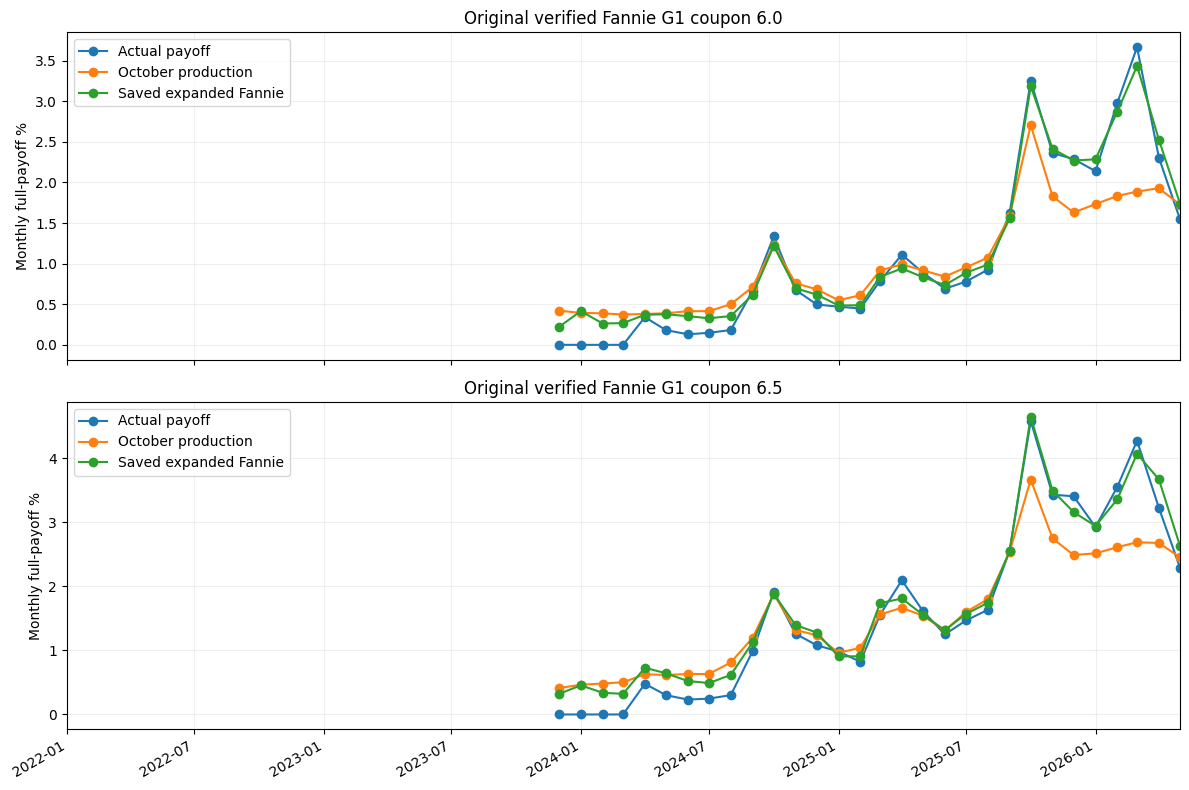

     month              group               status  loans  payoff_events  actual_payoff_pct  production_predicted_pct  expanded_predicted_pct  production_bias_pp  expanded_bias_pp  abs_bias_gain_pp    brier_gain  logloss_gain small_group_attention
2024-02-01     6.0_delinquent scored_retrospective      9              0           0.000000                  0.618471                0.456339            0.618471          0.456339          0.162132  1.868942e-05      0.001631                  True
2024-03-01     6.0_delinquent scored_retrospective     95              0           0.000000                  0.485781                0.465686            0.485781          0.465686          0.020095 -2.018039e-07      0.000201                  True
2024-04-01     6.0_delinquent scored_retrospective    157              1           0.312012                  0.536964                0.682216            0.224952          0.370204         -0.145252  1.166520e-06      0.000130                  True
2024-05-

In [21]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True)
for ax,coupon in zip(axes,['6.0','6.5']):
    g=ALL_RESULTS.loc[ALL_RESULTS.grouping.eq('coupon')&ALL_RESULTS.group.eq(coupon)].sort_values('month')
    for column,label in [('actual_payoff_pct','Actual payoff'),('production_predicted_pct','October production'),('expanded_predicted_pct','Saved expanded Fannie')]:
        ax.plot(pd.to_datetime(g.month),g[column],marker='o',label=label)
    ax.set_xlim(pd.Timestamp('2022-01-01'),pd.Timestamp('2026-05-01'))
    ax.set_title('Original verified Fannie G1 coupon '+coupon)
    ax.set_ylabel('Monthly full-payoff %');ax.legend();ax.grid(alpha=.2)
fig.autofmt_xdate();fig.tight_layout();fig.savefig(ROOT/'full53_coupon_predictions.png',dpi=160)
plt.show()
guard=ALL_RESULTS.loc[
    (ALL_RESULTS.grouping.eq('focus_current_young')&ALL_RESULTS.group.isin(['6.0_lt150k','6.0_500kplus','6.5_500kplus']))|
    (ALL_RESULTS.grouping.eq('status')&ALL_RESULTS.group.eq('6.0_delinquent'))|
    (ALL_RESULTS.grouping.eq('age_original_balance')&ALL_RESULTS.group.eq('6.5_24_59_500kplus'))]
guard.to_csv(ROOT/'priority_guardrail_months.csv',index=False)
print(guard.reindex(columns=COLUMNS+['small_group_attention']).to_string(index=False))


## Step 16 — Create and DOWNLOAD both checkpoint ZIPs
This step can run after partial progress, once setup through Step4 is ready. It creates a small-results ZIP and a FULL recovery ZIP in /content/g1_full53_downloads. The following two cells download them separately. Wait for each browser download to finish, then copy BOTH files from Downloads to Y:/OASIVE. A ZIP existing only in Colab is not a durable backup.

The FULL checkpoint includes the saved model, encoder, code, March reference, run specifications, source audit caches and completed monthly inputs/predictions. It does not duplicate the348 original training shards or save unscored panel months. The sandbox panel expires after30days.

After runtime loss, reopen THIS Colab notebook, upload its newest FULL output ZIP to /content, set RESTORE_MONTHLY_ZIP_PATH in Step1 to that file, and rerun setup/checked stages. Completed files/jobs are verified and reused. Do not use another cloud/no-bucket edition's output checkpoint or rewrite its recorded paths. Keep the two original input backups too.


In [22]:
from datetime import datetime,timezone
import uuid
EXPORT_DIR=Path('/content/g1_full53_downloads');EXPORT_DIR.mkdir(exist_ok=True)
assert not EXPORT_DIR.resolve().is_relative_to(ROOT.resolve())
CHECKPOINT=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S')+'_'+uuid.uuid4().hex[:8]
BACKUPS={}
for is_full in [False,True]:
    kind='FULL_recovery' if is_full else 'small_results'
    destination=EXPORT_DIR/(ROOT.name+'_'+CHECKPOINT+'_'+kind+'.zip')
    hashes={}
    with zipfile.ZipFile(destination,'w',zipfile.ZIP_DEFLATED) as z:
        for p in ROOT.rglob('*'):
            if not p.is_file() or p.name.endswith('.recovering'):continue
            if not is_full and (p.suffix in ['.parquet','.ubj','.joblib'] or 'recovered' in p.relative_to(ROOT).parts):continue
            relative=p.relative_to(ROOT).as_posix();z.write(p,relative);hashes[relative]=core.sha(p)
        z.writestr('monthly_recovery_hashes.json',json.dumps(hashes,indent=2))
    BACKUPS[kind]=destination
    print(kind,':',destination,'bytes:',destination.stat().st_size,'SHA256:',core.sha(destination))
print('Now run the SMALL download cell, then the FULL download cell. Save both on your laptop/Y drive.')


small_results : /content/g1_full53_downloads/g1_fannie_full53_colab_20261101_20261101T223733_7e881b55_small_results.zip bytes: 1910450 SHA256: 3513912519cdb38a15062c4e68a4e582d70aaae178961f64b3fe981f320ddafa
FULL_recovery : /content/g1_full53_downloads/g1_fannie_full53_colab_20261101_20261101T223733_7e881b55_FULL_recovery.zip bytes: 629460318 SHA256: d2cde514a79239568442fa89bed2bb3e210222afd11db791eba2aa77e99a1236
Now run the SMALL download cell, then the FULL download cell. Save both on your laptop/Y drive.


In [23]:
from google.colab import files
files.download(str(BACKUPS['small_results']))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
from google.colab import files
files.download(str(BACKUPS['FULL_recovery']))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Results files to send back for review

| File | Purpose |
|---|---|
| `all_53_calendar_months.csv` | All 53 months, explicit empty statuses, overall metrics where eligible loans exist |
| `membership_calendar_106_cells.csv` | Independent raw/eligible counts, prior-history exclusions and issued-pool counts for both coupons |
| `verified_inventory_106_cells.csv` | Full feature/label/UPB reconciliation |
| `potential_mapping_exclusions.csv` | Potential unresolved pool mapping coverage; does not redefine the primary cohort |
| `march_feature_vintage_bridge.csv` and `march_bridge.json` | Why reconstructed March features/results may differ from the previous snapshot |
| `monthly_coupon.csv` | Coupon-level month-by-month accuracy |
| `monthly_focus.csv` | Young current loans by original balance and the predeclared coupon-specific incentive bands |
| `monthly_status.csv` | Current/delinquent comparison |
| `all_53_month_groups.csv` | All subgroup results, including state/property/occupancy/channel |
| `period_summary.csv` | Exposure-weighted errors, with no signed-error cancellation |
| `priority_guardrail_months.csv` | Previously identified vulnerable groups |
| `months/YYYY-MM-01/paired_predictions.parquet` | Same-loan outcomes, features, weights and model probabilities |
| `months/YYYY-MM-01/category_coverage.csv` | Unseen categories under the frozen encoder |
| `preparation_spec.json`, `run_spec.json`, SQL, query jobs/checksums | Source/model/code provenance and reproducibility |

The primary table uses the four-class full-payoff target and before-calibration probabilities, not owner total unscheduled CPR or the served surface. Do not combine these units in one accuracy column. Preserve favorable and unfavorable months and low-event flags.

## If a cell stops

- **Missing runtime variables:** rerun this guide's setup cells from Step 1, restoring a FULL backup if the runtime was lost. Do not substitute summary CSVs for model/input assets.
- **ZIP is unreadable:** wait for the upload to finish and verify the exact filename. Do not retrain.
- **No early G1 rows:** expected before the declared target pools exist, if the census proves that. Do not manufacture observations or change the vintage to fill the chart.
- **Issued target pools but no servicing:** investigate date conventions, pool identifiers and raw coverage. Do not mark it a legitimate empty month automatically.
- **Prior-history exclusions:** retain their counts. Labels missing for otherwise eligible loans are a different problem and stop the run.
- **March membership differs:** inspect `march_membership_differences.csv`. Do not inner-join both arms down to a favorable common subset and retain the original full-cohort label.
- **Unexpected March features differ:** inspect the feature bridge and source snapshots. Only the specifically documented HPI-related differences are tolerated automatically.
- **Missing labels, duplicate keys or balance differences:** inspect the raw panel audit. Resolve the provenance/eligibility issue in a new version if required; do not zero-fill labels or arbitrarily deduplicate.
- **Source identity changed during preparation:** keep the failed run as evidence, start a new root/table identity and repeat preparation. Do not mix data versions.
- **Quota or cost cap:** review the SQL estimates and account limits. Do not alter the sample, features or months after seeing model outcomes.
- **Panel expired:** completed local reports remain recoverable from the FULL ZIP; unfinished scoring requires a new frozen reconstruction.

## What would establish progress on G1?

A strong historical result would show that the saved expanded model improves bias and probability losses across populated G1 months, especially the large-loan groups, while avoiding recurring deterioration in small, older and delinquent groups. This53-month calendar test answers that historical candidate question. It cannot, by itself, prove the split caused the gain or that future-month forecasts improved. Keep those two questions explicit in the report.

## Preparation validation

The reconstruction and reference SQL were dry-run against the actual accessible tables. No large reconstruction query, research panel creation or monthly production-model inference was executed while preparing this guide. Unit tests verify53-month coverage, empty-period handling, independent eligibility, missing labels, duplicate/join/balance checks and source/production-scope protection. The model and encoder replay is deliberately performed in Colab using the recorded package versions before large execution.
